In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from mapie.regression import SplitConformalRegressor, TimeSeriesRegressor
from mapie.conformity_scores import AbsoluteConformityScore

**1. Подготовка данных.** В каждой строке записана температура масла (`OT`) за один час. Убираем служебные столбцы, сортируем наблюдения по времени и проверяем, есть ли повторяющиеся даты.

In [2]:
SEED = 42

df = pd.read_csv("/Users/spharboxgmail.com/Documents/University/Conformal-prediction-intervals-/ETTh1.csv", parse_dates=['date'],  index_col='date')
df.drop(columns=['Id', 'Unnamed: 3'], inplace=True)
df.head(10)

/var/folders/rc/pjs_m6tj2dn7cd8895srh5_80000gn/T/ipykernel_1434/2414366777.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Id', 'Unnamed: 3'], inplace=True)


,OT
date,
2016-07-01 00:00:00,30.531000
2016-07-01 01:00:00,27.787001
2016-07-01 02:00:00,27.787001
2016-07-01 03:00:00,25.044001
2016-07-01 04:00:00,21.948000
2016-07-01 05:00:00,21.174000
2016-07-01 06:00:00,22.792000
2016-07-01 07:00:00,23.143999
2016-07-01 08:00:00,21.667000


In [3]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 17320 entries, 2016-07-01 00:00:00 to 2018-06-22 15:00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   OT      17320 non-null  float64
dtypes: float64(1)
memory usage: 270.6 KB


In [4]:
df.sort_index(inplace=True)
print(df.index.duplicated().sum())

0


/var/folders/rc/pjs_m6tj2dn7cd8895srh5_80000gn/T/ipykernel_1434/858748628.py:1: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_index(inplace=True)


**2. Выбор признаков.** На графике смотрим, повторяются ли изменения температуры через сутки. Для прогноза на 24 часа вперёд берём семь значений `OT` за тот же час в каждый из предыдущих семи дней.

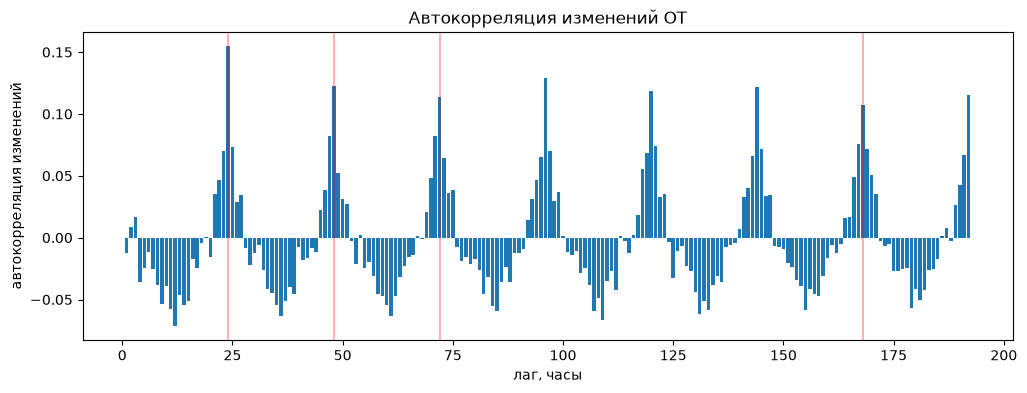

In [5]:
# автокорреляция часовых изменений OT: пики показывают циклы в данных
lags = range(1, 24 * 8 + 1)
acf = [df["OT"].diff().autocorr(lag=k) for k in lags]

plt.figure(figsize=(12, 4))
plt.bar(lags, acf)
for k in (24, 48, 72, 168):
    plt.axvline(k, color="red", alpha=0.3)
plt.xlabel("лаг, часы")
plt.ylabel("автокорреляция изменений")
plt.title("Автокорреляция изменений OT")
plt.show()

In [6]:
HORIZON = 24  # прогнозируем на сутки вперёд
LAGS = [24 * k for k in range(1, 8)]  # тот же час за каждый из последних 7 дней.

data = df.copy()  # df остаётся исходным рядом, признаки собираем в отдельной таблице
for lag in LAGS:
    data[f"lag_{lag}"] = data["OT"].shift(lag)

data = data.dropna()  # первые 168 часов без полного набора лагов
data.head(10)

,OT,lag_24,lag_48,lag_72,lag_96,lag_120,lag_144,lag_168
date,,,,,,,,
2016-07-08 00:00:00,31.093000,28.561001,28.913000,25.958000,21.667000,29.334999,21.104000,30.531000
2016-07-08 01:00:00,30.742001,28.771999,30.389999,25.958000,25.535999,26.028000,19.697001,27.787001
2016-07-08 02:00:00,29.334999,27.716999,31.514999,26.028000,27.857000,24.340000,20.049000,27.787001
2016-07-08 03:00:00,28.771999,28.139000,31.233999,28.913000,27.927999,26.450001,20.752001,25.044001
2016-07-08 04:00:00,29.124001,27.365000,30.531000,30.459999,24.621000,25.958000,21.385000,21.948000
2016-07-08 05:00:00,29.264000,26.732000,30.108999,31.375000,23.848000,24.059000,22.230000,21.174000
2016-07-08 06:00:00,29.405001,26.379999,30.320000,32.782001,23.073999,25.325001,20.260000,22.792000
2016-07-08 07:00:00,28.913000,25.395000,29.615999,31.726000,22.511000,23.636999,21.104000,23.143999
2016-07-08 08:00:00,29.896999,27.927999,30.531000,30.320000,21.667000,26.379999,20.612000,21.667000


**3. Разбиение и масштабирование.** Первые 60% ряда используем для обучения, следующие 20% для калибровки, последние 20% для проверки. Между частями пропускаем по 24 часа с учётом горизонта прогноза. Среднее и стандартное отклонение признаков считаем по обучающей части и применяем ко всем трём.

In [7]:
train, rest = train_test_split(data, test_size=0.4, shuffle=False)
cal, test = train_test_split(rest, test_size=0.5, shuffle=False)

# между частями пропускаем HORIZON часов, чтобы модель не знала значений,
# которые ещё неизвестны в момент первых прогнозов следующей части
cal, test = cal.iloc[HORIZON:], test.iloc[HORIZON:]

feature_cols = [f"lag_{lag}" for lag in LAGS]
X_train, y_train = train[feature_cols], train["OT"]
X_cal, y_cal = cal[feature_cols], cal["OT"]
X_test, y_test = test[feature_cols], test["OT"]

for name, part in [("train", train), ("cal", cal), ("test", test)]:
    print(f"{name:6s} {len(part):6d} строк  {part.index[0]:%Y-%m-%d} -> {part.index[-1]:%Y-%m-%d}")

train   10291 строк  2016-07-08 -> 2017-09-09
cal      3406 строк  2017-09-10 -> 2018-01-30
test     3407 строк  2018-01-31 -> 2018-06-22


In [8]:
scaler = StandardScaler().fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=feature_cols)
X_cal_scaled = pd.DataFrame(scaler.transform(X_cal), index=X_cal.index, columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=feature_cols)

for name, part in [("train", X_train_scaled), ("cal", X_cal_scaled), ("test", X_test_scaled)]:
    print(f"{name:6s} среднее = {part.values.mean():6.2f}   std = {part.values.std():.2f}")

train  среднее =  -0.00   std = 1.00
cal    среднее =  -1.15   std = 0.51
test   среднее =  -1.15   std = 0.43


**4. Прогноз температуры.** Обучаем линейную регрессию и сравниваем её среднюю абсолютную ошибку с простым прогнозом «завтра в этот час будет столько же, сколько сегодня». На графиках сравниваем прогноз с измерениями за весь период и отдельно за первые две недели теста.

In [9]:
model = LinearRegression().fit(X_train_scaled, y_train)

pred_train = model.predict(X_train_scaled)
pred_cal = model.predict(X_cal_scaled)
pred_test = model.predict(X_test_scaled)

print(pd.Series(model.coef_, index=feature_cols).round(3))
print(f"intercept = {model.intercept_:.3f}\n")

for name, X, y, pred in [("train", X_train, y_train, pred_train),
                         ("cal", X_cal, y_cal, pred_cal),
                         ("test", X_test, y_test, pred_test)]:
    mae_model = mean_absolute_error(y, pred)
    mae_naive = mean_absolute_error(y, X["lag_24"])  # наивный прогноз: как вчера в этот час
    print(f"{name:6s} MAE модели = {mae_model:.3f}   MAE наивного = {mae_naive:.3f}")

lag_24     5.822
lag_48    -0.423
lag_72     0.575
lag_96     0.847
lag_120   -0.407
lag_144    0.736
lag_168    1.074
dtype: float64
intercept = 17.135

train  MAE модели = 2.257   MAE наивного = 2.414
cal    MAE модели = 1.638   MAE наивного = 1.714
test   MAE модели = 1.684   MAE наивного = 1.710


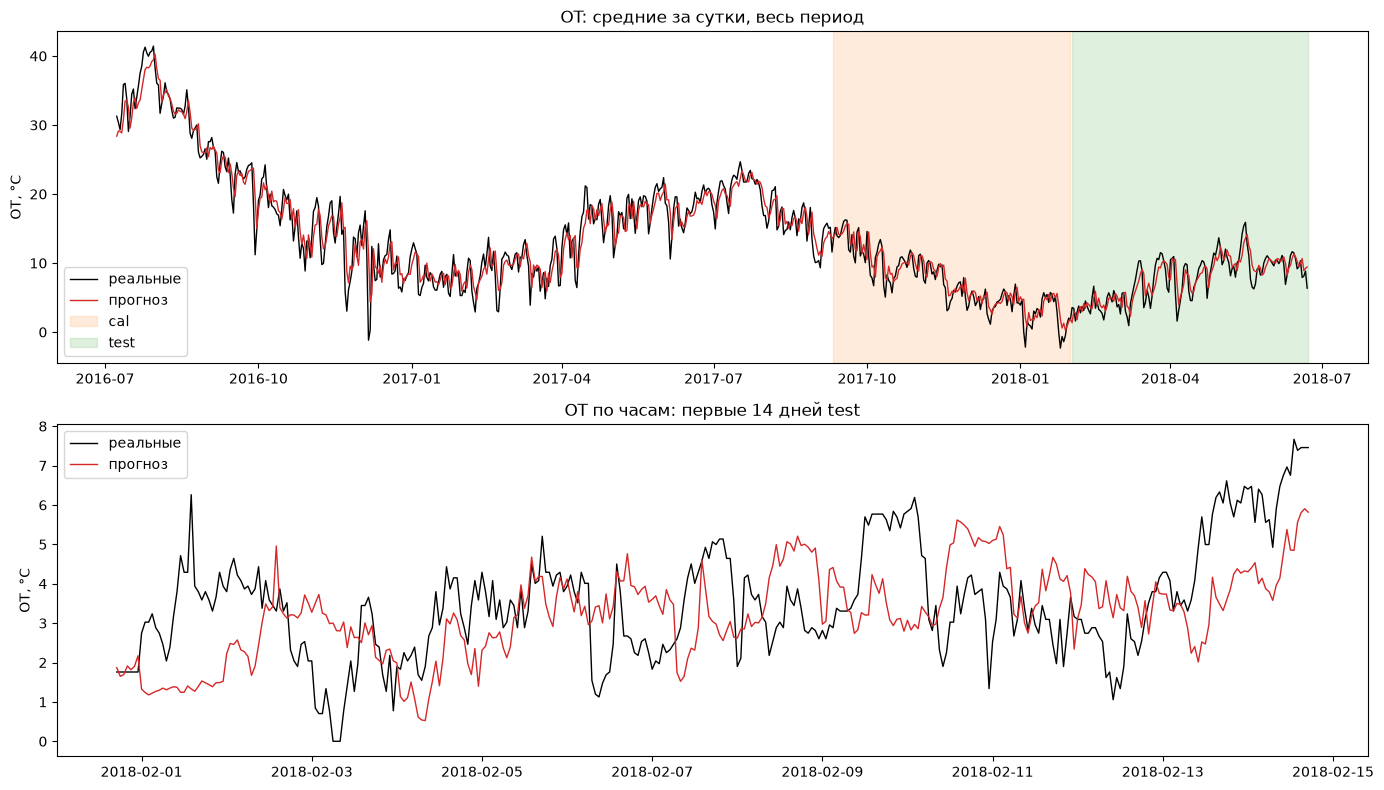

In [10]:
actual = pd.concat([y_train, y_cal, y_test])
pred = pd.concat([pd.Series(pred_train, index=y_train.index),
                  pd.Series(pred_cal, index=y_cal.index),
                  pd.Series(pred_test, index=y_test.index)])

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(actual.resample("D").mean(), color="black", lw=1, label="реальные")
axes[0].plot(pred.resample("D").mean(), color="tab:red", lw=1, label="прогноз")
axes[0].axvspan(y_cal.index[0], y_cal.index[-1], color="tab:orange", alpha=0.15, label="cal")
axes[0].axvspan(y_test.index[0], y_test.index[-1], color="tab:green", alpha=0.15, label="test")
axes[0].set_title("OT: средние за сутки, весь период")
axes[0].set_ylabel("OT, °C")
axes[0].legend()

zoom = slice(y_test.index[0], y_test.index[0] + pd.Timedelta(days=14))
axes[1].plot(actual[zoom], color="black", lw=1, label="реальные")
axes[1].plot(pred[zoom], color="tab:red", lw=1, label="прогноз")
axes[1].set_title("OT по часам: первые 14 дней test")
axes[1].set_ylabel("OT, °C")
axes[1].legend()

plt.tight_layout()
plt.show()

**5. Как строится интервал ACI.**

- Сортируем абсолютные ошибки на калибровочной выборке. По текущему уровню `a` выбираем ошибку `q` и строим интервал от `pred − q` до `pred + q`.
- Целевое покрытие — 90%. Когда узнаём о промахе, уменьшаем `a`, чтобы взять большую полуширину. При попадании понемногу увеличиваем `a`.
- Температуру, на которую выдали прогноз, измерят через сутки. Поэтому каждый результат учитываем при обновлении только через 24 шага.

In [11]:
ALPHA = 0.1
GAMMAS = [0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.05]


def aci(pred, y, cal_scores, alpha, gamma, delay):
    n = len(cal_scores)
    # Ранги 1…n соответствуют наблюдаемым ошибкам. Крайние ранги задают пустой и полный интервалы.
    ranked_scores = np.r_[-np.inf, np.sort(cal_scores), np.inf]
    T = len(pred)
    q = np.empty(T)
    alpha_t = np.empty(T)
    err = np.empty(T)
    a = alpha
    for t in range(T):
        if t >= delay:  # к моменту прогноза известна только ошибка прогноза t - delay
            a += gamma * (alpha - err[t - delay])
        k = int(np.ceil((n + 1) * (1 - a)))
        q[t] = ranked_scores[np.clip(k, 0, n + 1)]
        alpha_t[t] = a
        err[t] = abs(y[t] - pred[t]) > q[t]
    return pred - q, pred + q, alpha_t


def evaluate(y, lower, upper, alpha):
    y = np.asarray(y)
    covered = (y >= lower) & (y <= upper)
    width = upper - lower
    penalty = np.where(y < lower, lower - y, 0) + np.where(y > upper, y - upper, 0)
    return {
        "покрытие": covered.mean(),
        "медианная ширина": np.median(width),
        "interval score": np.mean(width + 2 / alpha * penalty),
    }

**6. Подбор шага обновления.** По первой половине калибровочной выборки считаем ошибки. На второй проверяем несколько значений `gamma`. Выбираем шаг с наименьшим `interval score`.

In [12]:
# подбор gamma на калибровочном сэте: первая половина — калибровка, вторая — проверка
half = len(y_cal) // 2
scores_tune = np.abs(y_cal.values[:half] - pred_cal[:half])
y_tune = y_cal.values[half + HORIZON:]
pred_tune = pred_cal[half + HORIZON:]

rows = []
for gamma in GAMMAS:
    lower, upper, _ = aci(pred_tune, y_tune, scores_tune, ALPHA, gamma, HORIZON)
    rows.append({"gamma": gamma, **evaluate(y_tune, lower, upper, ALPHA)})
tuning = pd.DataFrame(rows).set_index("gamma")

GAMMA = tuning["interval score"].idxmin()
print(f"выбранный gamma = {GAMMA}")
tuning.round(3)

выбранный gamma = 0.0005


,покрытие,медианная ширина,interval score
gamma,,,
0.0000,0.948,7.778,8.822
0.0005,0.923,7.211,8.757
0.0010,0.911,6.966,8.770
0.0020,0.899,6.731,8.820
0.0050,0.892,6.468,inf
0.0100,0.895,6.395,inf
0.0500,0.898,7.778,inf


**7. Проверка на тесте.** Используем ошибки со всей калибровочной выборки. При `gamma = 0` получаем split CP с постоянной шириной интервала. При выбранном `gamma` метод ACI меняет ширину по мере поступления измерений. Сравниваем покрытие, медианную ширину и `interval score`.

In [13]:
cal_scores = np.abs(y_cal.values - pred_cal)

lower_split, upper_split, _ = aci(pred_test, y_test.values, cal_scores, ALPHA, 0, HORIZON) # Вызов conformal prediction без gamma
lower_aci, upper_aci, alpha_t = aci(pred_test, y_test.values, cal_scores, ALPHA, GAMMA, HORIZON) # Вызов conformal prediction с выбранным gamma

results = pd.DataFrame({
    "split CP": evaluate(y_test, lower_split, upper_split, ALPHA),
    f"ACI (gamma={GAMMA})": evaluate(y_test, lower_aci, upper_aci, ALPHA),
})
results.round(3)

,split CP,ACI (gamma=0.0005)
покрытие,0.920,0.910
медианная ширина,7.225,7.043
interval score,9.368,9.384


**8. Сравнение с MAPIE.** Строим интервалы библиотечными методами для той же линейной регрессии. В ACI передаём очередное измерение с той же задержкой в 24 часа. В таблице сопоставляем результаты ручной и библиотечной реализаций.

In [ ]:
mapie_split = SplitConformalRegressor(model, confidence_level=1 - ALPHA, prefit=True)
mapie_split.conformalize(X_cal_scaled, y_cal)
_, pis = mapie_split.predict_interval(X_test_scaled)

lower_split_mapie, upper_split_mapie = pis[:, 0, 0], pis[:, 1, 0]

mapie_aci = TimeSeriesRegressor(model, method="aci", cv="prefit", conformity_score=AbsoluteConformityScore(sym=True))
mapie_aci.fit(X_train_scaled.values, y_train.values)
mapie_aci.conformalize(X_cal_scaled.values, y_cal.values)

X_test_np, y_test_np = X_test_scaled.values, y_test.values
lower_aci_mapie = np.empty(len(y_test_np))
upper_aci_mapie = np.empty(len(y_test_np))
for t in range(len(y_test_np)):
    s = t - HORIZON  # последняя точка, истинное значение которой уже известно
    if s >= 0:
        mapie_aci.adapt_conformal_inference(X_test_np[s:s + 1], y_test_np[s:s + 1], gamma=GAMMA, confidence_level=1 - ALPHA,)
    _, pis = mapie_aci.predict(X_test_np[t:t + 1], confidence_level=1 - ALPHA)
    lower_aci_mapie[t], upper_aci_mapie[t] = pis[0, 0, 0], pis[0, 1, 0]

comparison = pd.DataFrame({
    "split CP (вручную)": evaluate(y_test, lower_split, upper_split, ALPHA),
    "split CP (MAPIE)": evaluate(y_test, lower_split_mapie, upper_split_mapie, ALPHA),
    "ACI (вручную)": evaluate(y_test, lower_aci, upper_aci, ALPHA),
    "ACI (MAPIE)": evaluate(y_test, lower_aci_mapie, upper_aci_mapie, ALPHA),
}).T
print(f"split CP: макс. расхождение границ = {np.max(np.abs(upper_split - upper_split_mapie)):.2e}")
print(f"ACI: границы совпадают в {np.mean(np.isclose(upper_aci, upper_aci_mapie)):.1%} точек")
comparison.round(3)

split CP: макс. расхождение границ = 0.00e+00
ACI: границы совпадают в 20.3% точек


,покрытие,медианная ширина,interval score
split CP (вручную),0.920,7.225,9.368
split CP (MAPIE),0.920,7.225,9.368
ACI (вручную),0.910,7.043,9.384
ACI (MAPIE),0.908,7.033,9.383


**9. Чтение графиков.** На первом графике видны часы, когда температура вышла за границы интервала. Второй показывает долю попаданий за последние семь дней, третий — как в это время менялся рабочий уровень `alpha_t`.

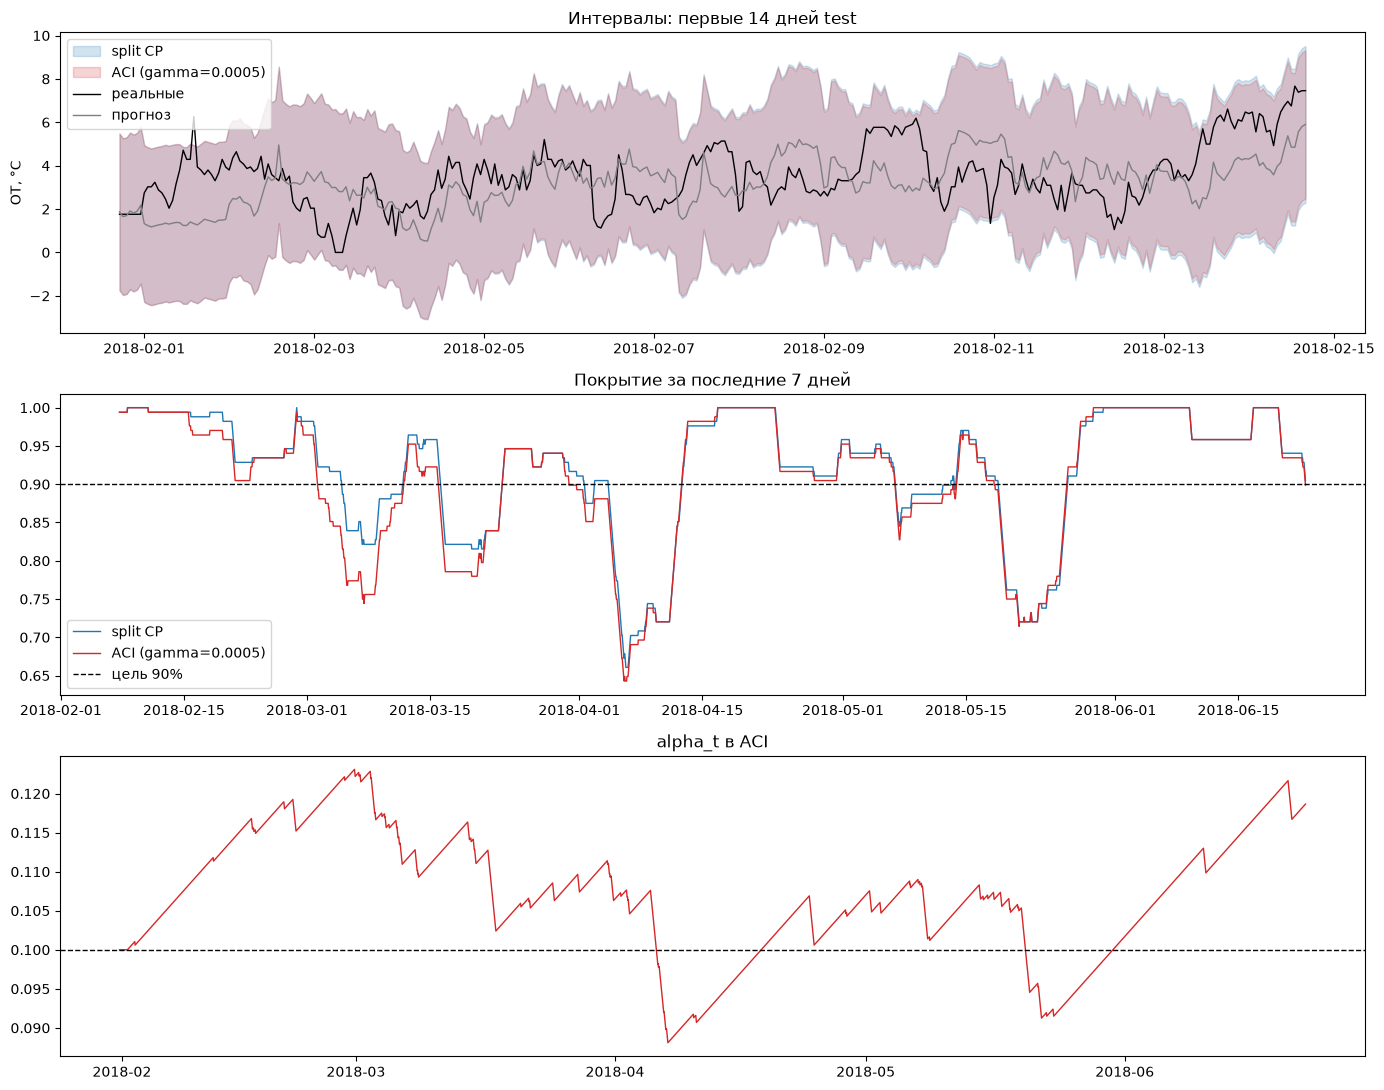

In [15]:
covered_split = pd.Series((y_test >= lower_split) & (y_test <= upper_split), index=y_test.index)
covered_aci = pd.Series((y_test >= lower_aci) & (y_test <= upper_aci), index=y_test.index)
first_days = slice(0, 24 * 14)

fig, axes = plt.subplots(3, 1, figsize=(14, 11))

idx = y_test.index[first_days]
axes[0].fill_between(idx, lower_split[first_days], upper_split[first_days], color="tab:blue", alpha=0.2, label="split CP")
axes[0].fill_between(idx, lower_aci[first_days], upper_aci[first_days], color="tab:red", alpha=0.2, label=f"ACI (gamma={GAMMA})")
axes[0].plot(idx, y_test.values[first_days], color="black", lw=1, label="реальные")
axes[0].plot(idx, pred_test[first_days], color="tab:gray", lw=1, label="прогноз")
axes[0].set_title("Интервалы: первые 14 дней test")
axes[0].set_ylabel("OT, °C")
axes[0].legend()

axes[1].plot(covered_split.rolling(168).mean(), color="tab:blue", lw=1, label="split CP")
axes[1].plot(covered_aci.rolling(168).mean(), color="tab:red", lw=1, label=f"ACI (gamma={GAMMA})")
axes[1].axhline(1 - ALPHA, color="black", ls="--", lw=1, label=f"цель {1 - ALPHA:.0%}")
axes[1].set_title("Покрытие за последние 7 дней")
axes[1].legend()

axes[2].plot(y_test.index, alpha_t, color="tab:red", lw=1)
axes[2].axhline(ALPHA, color="black", ls="--", lw=1)
axes[2].set_title("alpha_t в ACI")

plt.tight_layout()
plt.show()